# 04 — Modeling

## Goal
Train and compare forecasting models using a chronological split.

We will compare:
1. Previous-day baseline
2. Previous-week baseline
3. HistGradientBoosting
4. Random Forest
5. XGBoost (if installed)

Metrics:
- MAE
- RMSE
- MAPE
- R²

**No random train/test split is used.**


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The notebooks live inside /notebooks.
# Therefore the project root is one folder above the notebook folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(f"Raw data folder not found: {RAW_DATA_DIR}")

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DATA_DIR)
print("Processed data folder:", PROCESSED_DATA_DIR)


Project root: d:\Projects\Revenue Demand Forecasting
Raw data folder: d:\Projects\Revenue Demand Forecasting\data\raw
Processed data folder: d:\Projects\Revenue Demand Forecasting\data\processed


In [4]:
# Load the feature dataset created by Notebook 03.
FEATURED_DATA_PATH = PROCESSED_DATA_DIR / "train_featured.csv"

if not FEATURED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Feature dataset not found: {FEATURED_DATA_PATH}. "
        "Run Notebook 03 first."
    )

df = pd.read_csv(
    FEATURED_DATA_PATH,
    parse_dates=["date"]
)

print("Featured dataset shape:", df.shape)
display(df.head())


Featured dataset shape: (2950992, 35)


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,day_of_year,week_of_year,quarter,is_weekend,is_month_start,is_month_end,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_rolling_mean_7,sales_rolling_std_7,sales_rolling_mean_14,sales_rolling_std_14,sales_rolling_mean_28,sales_rolling_std_28,city,state,type,cluster,transactions,dcoilwtico,holiday_count,holiday_types,is_holiday
0,51053,2013-01-29,41,BEAUTY,0.00,0,2013,1,29,1,29,5,1,0,0,0,4.00,1.00,3.00,0.00,2.00,1.29,2.07,1.27,1.89,1.42,Machala,El Oro,D,4,680.00,97.62,0.00,NaN,0.00
1,50800,2013-01-29,34,GROCERY II,3.00,0,2013,1,29,1,29,5,1,0,0,0,1.00,3.00,32.00,0.00,6.29,4.42,8.64,8.03,8.57,6.91,Guayaquil,Guayas,B,6,"2,306.00",97.62,0.00,NaN,0.00
2,50398,2013-01-29,23,CLEANING,470.00,0,2013,1,29,1,29,5,1,0,0,0,570.00,654.00,612.00,0.00,587.14,66.49,592.21,75.84,619.50,158.89,Ambato,Tungurahua,D,9,"1,139.00",97.62,0.00,NaN,0.00
3,50562,2013-01-29,28,CELEBRATION,0.00,0,2013,1,29,1,29,5,1,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Guayaquil,Guayas,E,10,815.00,97.62,0.00,NaN,0.00
4,49967,2013-01-29,11,BREAD/BAKERY,477.00,0,2013,1,29,1,29,5,1,0,0,0,519.00,440.00,462.00,0.00,513.71,56.13,514.14,54.08,512.82,138.10,Cayambe,Pichincha,B,6,"2,095.00",97.62,0.00,NaN,0.00


In [5]:
# Chronological train / validation / test split.
df = df.sort_values("date").reset_index(drop=True)

unique_dates = sorted(df["date"].unique())

train_end = int(len(unique_dates) * 0.70)
validation_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_end]
validation_dates = unique_dates[train_end:validation_end]
test_dates = unique_dates[validation_end:]

train_df = df[df["date"].isin(train_dates)].copy()
validation_df = df[df["date"].isin(validation_dates)].copy()
test_df = df[df["date"].isin(test_dates)].copy()

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

print("\nDate ranges:")
print("Train:", train_df["date"].min(), "to", train_df["date"].max())
print("Validation:", validation_df["date"].min(), "to", validation_df["date"].max())
print("Test:", test_df["date"].min(), "to", test_df["date"].max())


Train: (2065338, 35)
Validation: (441936, 35)
Test: (443718, 35)

Date ranges:
Train: 2013-01-29 00:00:00 to 2016-04-04 00:00:00
Validation: 2016-04-05 00:00:00 to 2016-12-08 00:00:00
Test: 2016-12-09 00:00:00 to 2017-08-15 00:00:00


In [6]:
# Evaluation functions.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    non_zero = actual != 0
    mape = (
        np.mean(
            np.abs(
                (actual[non_zero] - predicted[non_zero])
                / actual[non_zero]
            )
        ) * 100
        if non_zero.any()
        else 0
    )

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": mape,
        "R2": r2_score(actual, predicted),
    }


In [7]:
# Baseline 1: previous day
baseline_1 = validation_df["sales_lag_1"]

metrics_baseline_1 = calculate_metrics(
    validation_df["sales"],
    baseline_1
)

# Baseline 2: previous week
baseline_7 = validation_df["sales_lag_7"]

metrics_baseline_7 = calculate_metrics(
    validation_df["sales"],
    baseline_7
)

baseline_results = pd.DataFrame([
    {"Model": "Previous Day Baseline", **metrics_baseline_1},
    {"Model": "Previous Week Baseline", **metrics_baseline_7},
])

display(baseline_results)


,Model,MAE,RMSE,MAPE,R2
0,Previous Day Baseline,120.95,620.69,57.18,0.77
1,Previous Week Baseline,87.62,569.01,52.08,0.80


In [8]:
# Prepare ML features.
TARGET = "sales"

DROP_COLUMNS = [
    TARGET,
    "date",
    "holiday_types",
]

X_train = train_df.drop(columns=DROP_COLUMNS, errors="ignore")
y_train = train_df[TARGET]

X_validation = validation_df.drop(columns=DROP_COLUMNS, errors="ignore")
y_validation = validation_df[TARGET]

X_test = test_df.drop(columns=DROP_COLUMNS, errors="ignore")
y_test = test_df[TARGET]

categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_columns = X_train.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("Numeric features:", len(numeric_columns))
print("Categorical features:", categorical_columns)


Numeric features: 28
Categorical features: ['family', 'city', 'state', 'type']


In [9]:
# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])


In [10]:
# Define models.
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

models = {
    "HistGradientBoosting": HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ),
    "RandomForest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    )
}

try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
    print("XGBoost is available.")
except ImportError:
    print("XGBoost is not installed. Continuing without it.")


XGBoost is available.


In [11]:
# Train models and compare validation performance.
results = []
trained_models = {}

for model_name, model in models.items():
    print(f"\nTraining: {model_name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    validation_prediction = pipeline.predict(X_validation)

    metrics = calculate_metrics(
        y_validation,
        validation_prediction
    )

    results.append({
        "Model": model_name,
        **metrics
    })

    trained_models[model_name] = pipeline

validation_results = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(validation_results)



Training: HistGradientBoosting

Training: RandomForest

Training: XGBoost


,Model,MAE,RMSE,MAPE,R2
0,RandomForest,56.11,388.37,54.11,0.91
1,XGBoost,60.15,389.58,59.46,0.91
2,HistGradientBoosting,61.90,390.95,52.28,0.91


In [12]:
# Add baselines to the comparison.
all_validation_results = pd.concat(
    [
        baseline_results,
        validation_results
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

display(all_validation_results)


,Model,MAE,RMSE,MAPE,R2
0,RandomForest,56.11,388.37,54.11,0.91
1,XGBoost,60.15,389.58,59.46,0.91
2,HistGradientBoosting,61.90,390.95,52.28,0.91
3,Previous Week Baseline,87.62,569.01,52.08,0.80
4,Previous Day Baseline,120.95,620.69,57.18,0.77


In [13]:
# Select the best ML model based on validation MAE.
best_model_name = validation_results.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best ML model:", best_model_name)


Best ML model: RandomForest


In [14]:
# Final evaluation on the untouched chronological test period.
test_prediction = best_model.predict(X_test)

test_metrics = calculate_metrics(
    y_test,
    test_prediction
)

print("Final test metrics:")
display(pd.DataFrame([test_metrics], index=[best_model_name]))


Final test metrics:


,MAE,RMSE,MAPE,R2
RandomForest,68.00,266.97,61.05,0.96


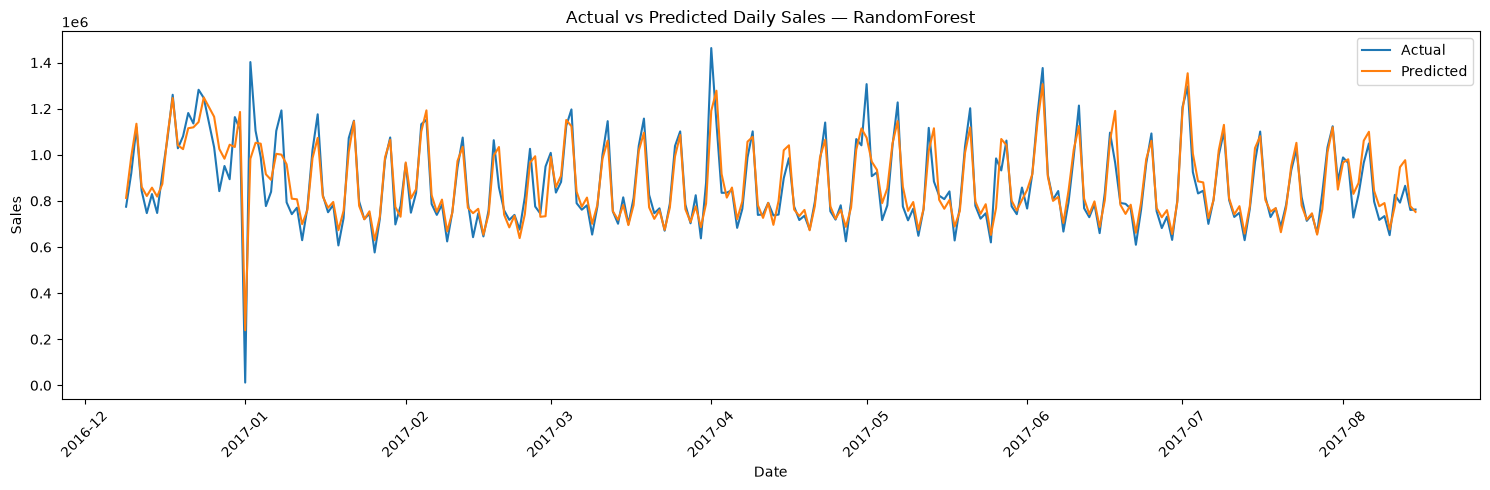

In [15]:
# Actual vs predicted daily sales.
comparison = pd.DataFrame({
    "date": test_df["date"].values,
    "actual": y_test.values,
    "predicted": test_prediction
})

daily_comparison = (
    comparison.groupby("date", as_index=False)
    .agg(
        actual=("actual", "sum"),
        predicted=("predicted", "sum")
    )
)

plt.figure(figsize=(15, 5))
plt.plot(
    daily_comparison["date"],
    daily_comparison["actual"],
    label="Actual"
)
plt.plot(
    daily_comparison["date"],
    daily_comparison["predicted"],
    label="Predicted"
)
plt.title(f"Actual vs Predicted Daily Sales — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [16]:
# Error analysis.
error_df = pd.DataFrame({
    "date": test_df["date"].values,
    "actual": y_test.values,
    "predicted": test_prediction
})

error_df["error"] = (
    error_df["actual"] - error_df["predicted"]
)
error_df["absolute_error"] = error_df["error"].abs()

print("Mean absolute error:", error_df["absolute_error"].mean())

print("\nLargest errors:")
display(
    error_df.sort_values(
        "absolute_error",
        ascending=False
    ).head(10)
)


Mean absolute error: 67.99812981522213

Largest errors:


,date,actual,predicted,error,absolute_error
6247,2016-12-12,"31,125.52","1,932.92","29,192.61","29,192.61"
201419,2017-04-02,"38,422.62","9,558.34","28,864.28","28,864.28"
219036,2017-04-11,"20,602.00","2,155.37","18,446.63","18,446.63"
219413,2017-04-12,"20,106.00","3,730.12","16,375.88","16,375.88"
20280,2016-12-20,"29,666.00","15,246.79","14,419.21","14,419.21"
351479,2017-06-25,"17,614.00","3,612.89","14,001.11","14,001.11"
184806,2017-03-23,"14,250.00","1,424.97","12,825.03","12,825.03"
19869,2016-12-20,"14,665.00","2,248.32","12,416.68","12,416.68"
68281,2017-01-17,"13,409.00",996.79,"12,412.21","12,412.21"
42316,2017-01-02,"23,966.00","12,591.27","11,374.73","11,374.73"


In [17]:
# Save model comparison and final metrics.
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODELS_DIR = PROJECT_ROOT / "models"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

all_validation_results.to_csv(
    ARTIFACTS_DIR / "model_comparison_validation.csv",
    index=False
)

pd.DataFrame([test_metrics]).to_csv(
    ARTIFACTS_DIR / "final_test_metrics.csv",
    index=False
)

import joblib

joblib.dump(
    best_model,
    MODELS_DIR / "best_forecasting_model.joblib"
)

pd.DataFrame({
    "date": test_df["date"].values,
    "actual_sales": y_test.values,
    "predicted_sales": np.clip(test_prediction, 0, None)
}).to_csv(
    ARTIFACTS_DIR / "test_predictions.csv",
    index=False
)

print("Saved:")
print(MODELS_DIR / "best_forecasting_model.joblib")
print(ARTIFACTS_DIR / "model_comparison_validation.csv")
print(ARTIFACTS_DIR / "final_test_metrics.csv")
print(ARTIFACTS_DIR / "test_predictions.csv")


Saved:
d:\Projects\Revenue Demand Forecasting\models\best_forecasting_model.joblib
d:\Projects\Revenue Demand Forecasting\artifacts\model_comparison_validation.csv
d:\Projects\Revenue Demand Forecasting\artifacts\final_test_metrics.csv
d:\Projects\Revenue Demand Forecasting\artifacts\test_predictions.csv


## Modeling conclusion

We have now:
- established simple baselines
- trained multiple ML models
- selected the best model using validation data
- evaluated it once on the future test period
- saved the model and evaluation artifacts

The next production step is to make the same logic reusable through `src/` and then expose prediction through FastAPI.
